In [2]:
import numpy as np
import scipy
import scipy.linalg
import random
import math
import matplotlib.pyplot as plt

In [11]:
def normalize(U):
    V=np.empty((L,N),dtype=np.complex_)
    for j in range(N):
        V[:,j]=U[:,j]
        for k in range(j):
            V[:,j]=V[:,j]-np.vdot(U[:,j],V[:,k])*V[:,k]
        V[:,j]=V[:,j]/np.linalg.norm(V[:,j])
    return V  

In [33]:
L=6
length=int(L/2)
N=int(L/2)

In [38]:
N

3

In [34]:
h=np.zeros((L,L))
p=1
for i in range(L):
    for j in range(L):
        if (i==j-1 or i==j+1):
            h[i,j]=p
print(h)

[[0. 1. 0. 0. 0. 0.]
 [1. 0. 1. 0. 0. 0.]
 [0. 1. 0. 1. 0. 0.]
 [0. 0. 1. 0. 1. 0.]
 [0. 0. 0. 1. 0. 1.]
 [0. 0. 0. 0. 1. 0.]]


In [35]:
np.arange(0,10,0.5)

array([0. , 0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. , 5.5, 6. ,
       6.5, 7. , 7.5, 8. , 8.5, 9. , 9.5])

[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
0
0.0
0.986218719922239
1.82360189747965
1
0.0
0.7688505563992274
1.4120149309509515
2
0.0
0.7733892080635161
1.2285523456343255
3
0.0
0.7462106821517186
1.1424430970950012
4
0.0
0.7454619861573707
1.112484624346487
5
0.0
0.6564636581342285
1.0084558221145046
6
0.0
0.6586992357846867
1.1442670533699464
7
0.0
0.6760897586279122
0.981701089400388
8
0.0
0.6758254753414967
1.0130010112741146
9
0.0
0.5947549900483381
0.9835491413039013
10
0.0
0.5940475718382187
0.9343424998118647
[[0.         0.98621872 1.8236019 ]
 [0.         0.76885056 1.41201493]
 [0.         0.77338921 1.22855235]
 [0.         0.74621068 1.1424431 ]
 [0.         0.74546199 1.11248462]
 [0.         0.65646366 1.00845582]
 [0.         0.65869924 1.14426705]
 [0.         0.67608976 0.98170109]
 [0.         0.67582548 1.01300101]
 [0.         0.59475499 0.98354914]
 [0.         0.59404757 0.9

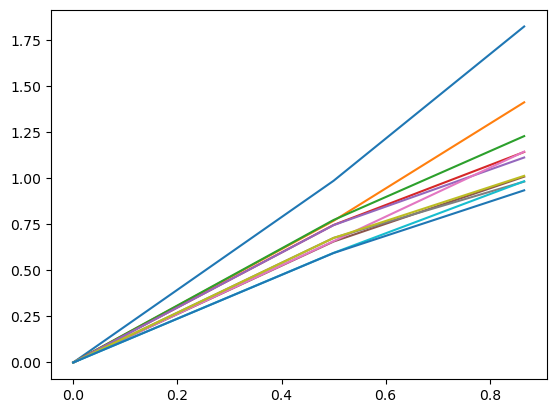

In [43]:
dt=0.5
time=np.arange(0,10,dt)
w=11
gamma=np.linspace(0,1,w)
A=100
S_avg=np.zeros((w,length))
print(S_avg)
f=np.zeros(length)
for l in range(length):
    f[l]=math.sin(math.pi*l/L)
for g in range(w):
    print(g)
    for l in range(length):
        S_tot=0
        D_tot=np.zeros((L,L),dtype=np.complex_)
        for a in range(A):
            U=np.zeros((L,N),dtype=np.complex_)
            for k in range(N):
                U[2*k+1,k]=1+1j*0
                
            for t in time:
                Ut=np.conjugate(np.transpose(U))
                D=np.transpose(np.dot(U,Ut))       
                n=np.zeros(L,dtype=np.complex_)
                for j in range(L):
                    n[j]=D[j,j]
                M=np.zeros((L,L),dtype=np.complex_)
                for i in range(L):
                    M[i,i]=random.gauss(mu=0, sigma=np.sqrt(gamma[g]*dt))/dt+gamma[g]*(2*n[i]-1)/2
                h1=h+1j*M 
                U=np.dot(scipy.linalg.expm(-1j*dt*h1),U)
                U=normalize(U) 
            D=np.transpose(np.dot(U,np.conjugate(np.transpose(U))))
            D_red=np.zeros((l,l),dtype=np.complex_)
            
            for i in range(l):
                for j in range(l):
                    D_red[i,j]=D[i,j]

            
            ev=np.round(np.linalg.eig(D_red)[0].real,3)
            S1=0
            for i in range(l):
                if(ev[i]>=1):
                    ev[i]=1-0.001
                if(ev[i]<=0):
                    ev[i]=0.001
                S1=S1-ev[i]*math.log2(ev[i])-(1-ev[i])*math.log2(1-ev[i])
            S_tot=S_tot+S1
            
        S_avg[g,l]=S_tot/A
        print(S_avg[g,l])

print(S_avg)        
    
for g in range(w):
    plt.plot(f,S_avg[g,:])

In [31]:
S_avg

array([[0.        , 0.34698129],
       [0.        , 0.56395593],
       [0.        , 0.64422336],
       [0.        , 0.6601854 ],
       [0.        , 0.66819821],
       [0.        , 0.60120285],
       [0.        , 0.66320659],
       [0.        , 0.62940941],
       [0.        , 0.59328429],
       [0.        , 0.64723305],
       [0.        , 0.58437993]])

In [1]:
#Benchmark Test

In [90]:
def benchmark(L,t1,t2,dt):
    length=int(L/2)
    N=int(L/2)
    h=np.zeros((L,L))
    p=1
    for i in range(L):
        for j in range(L):
            if (i==j-1 or i==j+1):
                h[i,j]=p
    S=[]
    S1=[]
    tf=np.arange(t1,t2,dt)
    std=0
    for q in tf:
        time=np.arange(0,q,dt)
        U=np.zeros((L,N),dtype=np.complex_)
        U1=np.zeros((L,N),dtype=np.complex_)
        for k in range(N):
            U[2*k+1,k]=1+1j*0
            U1[2*k+1,k]=1+1j*0
        for t in time:
    #         Ut=np.conjugate(np.transpose(U))
    #         D=np.transpose(np.dot(U,Ut))       
    #         n=np.zeros(L,dtype=np.complex_)
    #         for j in range(L):
    #             n[j]=D[j,j]

        #                 M=np.zeros((L,L),dtype=np.complex_)
        #                 for i in range(L):
        #                     M[i,i]=random.gauss(mu=0, sigma=np.sqrt(gamma[g]*dt))/dt+gamma[g]*(2*n[i]-1)/2
        #                 h1=h+1j*M
            U=np.dot(scipy.linalg.expm(-1j*dt*h),U)
        Ut=np.conjugate(np.transpose(U))
        D=np.transpose(np.dot(U,Ut))
        D_red=np.zeros((length,length),dtype=np.complex_)
        for i in range(length):
            for j in range(length):
                D_red[i,j]=D[i,j]
        ev=np.round(np.linalg.eig(D_red)[0].real,3)
        tot=0
        for i in range(length):
            if(ev[i]>=1):
                ev[i]=1-0.001
            if(ev[i]<=0):
                ev[i]=0.001
            tot=tot-ev[i]*math.log2(ev[i])-(1-ev[i])*math.log2(1-ev[i])
        S.append(tot)
        U1=np.dot(scipy.linalg.expm(-1j*q*h),U1)
        Ut=np.conjugate(np.transpose(U1))
        D=np.transpose(np.dot(U1,Ut))
        D_red=np.zeros((length,length),dtype=np.complex_)
        for i in range(length):
            for j in range(length):
                D_red[i,j]=D[i,j]
        ev=np.round(np.linalg.eig(D_red)[0].real,3)
        tot=0
        for i in range(length):
            if(ev[i]>=1):
                ev[i]=1-0.001
            if(ev[i]<=0):
                ev[i]=0.001
            tot=tot-ev[i]*math.log2(ev[i])-(1-ev[i])*math.log2(1-ev[i])
        S1.append(tot)
    for i in range(len(S)):
        std=std+(S[i]-S1[i])**2
    std=np.sqrt(std/len(S))
    return std
        
#     plt.plot(tf,np.array(S),label="discrete")
#     plt.plot(tf,np.array(S1), label="continuous")
#     plt.xlabel("time")
#     plt.ylabel("Entanglement Entropy")
#     plt.title(f"time steps = {dt}")
#     plt.legend() 

         

In [139]:
benchmark(0.5)

0.010380316549556404

In [147]:
def find_dt(t_fin,L):
    dt_arr=np.linspace(0.01,0.1,50)
    t_in=1
    std=np.zeros(len(dt_arr))
    # std_arr2=np.zeros(50)
    for i in range(len(dt_arr)):
        std[i]=benchmark(L,t_in,t_fin,dt_arr[i])
        
    plt.plot(dt_arr,std,label=f"tf={t_fin}, L={L}")
    plt.legend()
    
# plt.plot(t_fin,std_arr1, label="L=4")
# plt.plot(t_fin,std_arr2, label="L=6")
# plt.xlabel("tf")
# plt.ylabel("std")
# plt.title("dt=0.03, ti=1")
# plt.legend()

In [148]:
find_dt(10,10)
find_dt(10,20)


KeyboardInterrupt: 

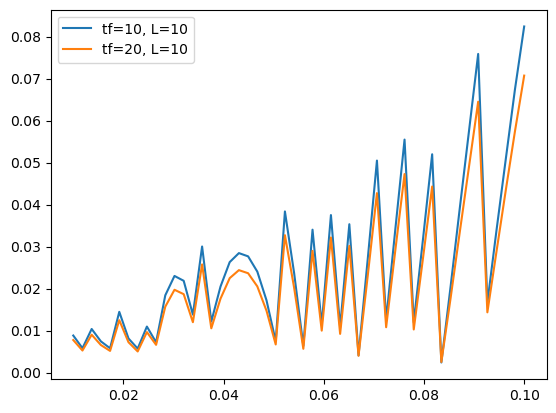

In [149]:
find_dt(10,10)
find_dt(20,10)